# icon_0.1deg: the last snapshot

Surface fields, sections, and a close look at the Amundsen Sea shelf where the
dt = 144 run went unstable.

The grid is 3600 x 2295 x 128, so ONE 3-D field is 8.5 GB in float64. Nothing
below loads a whole 3-D field: the maps take one level per rank block, the
sections take one row or column, and the region section takes a window. Ask
for `load(var)` with `k=None` only if you mean it.

In [1]:
import os, glob, re
import numpy as np
import matplotlib.pyplot as plt
from netCDF4 import Dataset

RUNDIR   = '/work/uo0780/u241155/pyOM3_real/icon01_spinup'
GRIDFILE = os.path.join(RUNDIR, 'grid_topo.nc')
SNAPGLOB = 'raw_ocean_icon01_seg*'       # one directory per job segment
STEP     = None                          # None = the newest, -2 = the one before

# the cell the dt = 144 run died in, and the sections to cut
PROBLEM   = (-150.2, -76.25)             # lon, lat: Amundsen shelf
SECTION_LON = [-150.2, -30.0, 180.0]     # meridional sections
SECTION_LAT = [-60.0, 0.0, 40.0]         # zonal sections
ZMAX      = 1500.0                       # depth limit of the section plots

# Every reader below opens one file per rank, so a surface map is 7650 file
# opens: latency bound, and a thread pool is the whole difference between a
# minute and a few seconds. Raise it until the time stops falling.
NTHREAD   = 32

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['image.cmap'] = 'RdYlBu_r'

## The snapshot, the grid, the block loader

In [2]:
segdirs = sorted(d for d in glob.glob(os.path.join(RUNDIR, SNAPGLOB))
                 if not d.endswith('_alarm'))
if not segdirs:
    raise SystemExit('no snapshot directory matching %s in %s' % (SNAPGLOB, RUNDIR))
SNAPDIR, steps = None, []
for d in reversed(segdirs):
    s = sorted({int(re.search(r'n=(\d+)$', p).group(1))
                for p in glob.glob(os.path.join(d, 'pe=*', 'n=*'))})
    if s:
        SNAPDIR, steps = d, s
        break
step = steps[-1] if STEP is None else (steps[STEP] if STEP < 0 else STEP)

xt = np.load(os.path.join(SNAPDIR, 'xt.npy'))
yt = np.load(os.path.join(SNAPDIR, 'yt.npy'))
zt = np.load(os.path.join(SNAPDIR, 'zt.npy'))          # height above the bottom
npx, npy = np.load(os.path.join(SNAPDIR, 'decomposition.npy'))
nx, ny, nz = len(xt), len(yt), len(zt)

with Dataset(GRIDFILE) as f:
    kbot = np.asarray(f.variables['kbot'][:], int)
    dzt  = np.asarray(f.variables['dzt'][:], float)     # bottom first

depth_of = dzt.sum() - zt                               # metres below the surface
wet = (np.arange(nz)[:, None, None] >= (kbot - 1)[None]) & (kbot > 0)[None]
below = np.cumsum(dzt[::-1])[::-1]
col_depth = np.where(kbot > 0, below[np.clip(kbot - 1, 0, nz - 1)], 0.0)
nwet_col = np.where(kbot > 0, nz - kbot + 1, 0)

t_days = float(np.load(glob.glob(os.path.join(SNAPDIR, 'pe=*', 'n=%d' % step,
                                              't.npy'))[0]))/86400.
print('%s   step %d   t = %.3f d   (%d steps: %s)'
      % (os.path.basename(SNAPDIR), step, t_days, len(steps), steps))
print('grid %d x %d x %d on %d x %d ranks | %d wet cells | deepest column %.0f m '
      '(%d levels) | top cell %.2f m'
      % (nx, ny, nz, npx, npy, wet.sum(), col_depth.max(), nwet_col.max(), dzt[-1]))

raw_ocean_icon01_seg0000000   step 12000   t = 10.000 d   (3 steps: [0, 6000, 12000])
grid 3600 x 2295 x 128 on 90 x 85 ranks | 545210227 wet cells | deepest column 6100 m (128 levels) | top cell 2.05 m


In [3]:
x_blk, y_blk = (nx-1)//npx + 1, (ny-1)//npy + 1
BLOCKS = []
for by in range(npy):
    for bx in range(npx):
        BLOCKS.append((by*npx + bx, by*y_blk, min((by+1)*y_blk, ny),
                       bx*x_blk, min((bx+1)*x_blk, nx)))

def _npy(pe, var):
    return os.path.join(SNAPDIR, 'pe=%d' % pe, 'n=%d' % step, '%s.npy' % var)

from concurrent.futures import ThreadPoolExecutor

def _each(fn, blocks=None):
    """fn(block) over the blocks, in parallel. numpy releases the GIL in the
    copy, and the cost is the file opens, so threads are the right tool."""
    with ThreadPoolExecutor(NTHREAD) as ex:
        return list(ex.map(fn, BLOCKS if blocks is None else blocks))

def load(var, k=None):
    """One level (k, 0 = sea floor, -1 = surface), a 2-D field, or -- only if
    you mean it -- the whole 3-D field, 8.5 GB in float64."""
    out = [None]
    def one(b):
        pe, j0, j1, i0, i1 = b
        a = np.load(_npy(pe, var), mmap_mode='r')
        if a.ndim == 2:
            return b, np.array(a), 2
        return b, (np.array(a) if k is None else np.array(a[k])), a.ndim
    res = _each(one)
    nd = res[0][2]
    if nd == 3 and k is None:
        out = np.empty((nz, ny, nx))
        for (pe, j0, j1, i0, i1), a, _ in res:
            out[:, j0:j1, i0:i1] = a
    else:
        out = np.empty((ny, nx))
        for (pe, j0, j1, i0, i1), a, _ in res:
            out[j0:j1, i0:i1] = a
    return out

def load_rows(var, j):
    """The full (nz, nx) slab at global row j: only the blocks on that row."""
    sel = [b for b in BLOCKS if b[1] <= j < b[2]]
    out = np.full((nz, nx), np.nan)
    def one(b):
        pe, j0, j1, i0, i1 = b
        return b, np.array(np.load(_npy(pe, var), mmap_mode='r')[:, j - j0])
    for (pe, j0, j1, i0, i1), a in _each(one, sel):
        out[:, i0:i1] = a
    return out

def load_cols(var, i):
    """The full (nz, ny) slab at global column i."""
    sel = [b for b in BLOCKS if b[3] <= i < b[4]]
    out = np.full((nz, ny), np.nan)
    def one(b):
        pe, j0, j1, i0, i1 = b
        return b, np.array(np.load(_npy(pe, var), mmap_mode='r')[:, :, i - i0])
    for (pe, j0, j1, i0, i1), a in _each(one, sel):
        out[:, j0:j1] = a
    return out

def load_box(var, js, je, isl):
    """(nz, je-js, len(isl)) window, for a region. isl may wrap in x."""
    sel = [b for b in BLOCKS if not (b[2] <= js or b[1] >= je)
           and any(b[3] <= ii < b[4] for ii in isl)]
    out = np.full((nz, je - js, len(isl)), np.nan)
    def one(b):
        pe, j0, j1, i0, i1 = b
        cols = [(n, ii - i0) for n, ii in enumerate(isl) if i0 <= ii < i1]
        a = np.load(_npy(pe, var), mmap_mode='r')
        jj0, jj1 = max(j0, js), min(j1, je)
        return (jj0, jj1, np.array([s[0] for s in cols]),
                np.array(a[:, jj0-j0:jj1-j0][:, :, np.array([s[1] for s in cols])]))
    for jj0, jj1, dst, a in _each(one, sel):
        out[:, jj0-js:jj1-js, dst] = a
    return out

def block_of(j, i):
    for pe, j0, j1, i0, i1 in BLOCKS:
        if j0 <= j < j1 and i0 <= i < i1:
            return pe, j - j0, i - i0
    raise IndexError((j, i))

def mask(a, k=None):
    m = wet if a.ndim == 3 else (wet[k] if k is not None else kbot > 0)
    return np.where(m, a, np.nan)

def ij_of(lon, lat):
    return int(np.argmin(np.abs(yt - lat))), int(np.argmin(np.abs(
        np.mod(xt - lon + 180.0, 360.0) - 180.0)))

print('variables written:', sorted(os.path.basename(p)[:-4] for p in
      glob.glob(os.path.join(SNAPDIR, 'pe=0', 'n=%d' % step, '*.npy'))))

variables written: ['K_diss_E', 'K_diss_L', 'p_h', 'p_s', 'salt', 't', 'temp', 'tke', 'u', 'v', 'w']


## Surface fields

SST, SSS, the surface speed, the sea level and the surface TKE. Two things make this slow at 3600 x 2295 and both have a knob.

**Reading.** One surface level is one file open per rank, so five fields is
38000 opens. `NTHREAD` in the first cell turns that from a minute into
seconds.

**Drawing.** `pcolormesh` draws one quad per cell: the full field is 8.3
million of them per panel, which matplotlib takes tens of seconds over. `SUB`
subsamples it (3 leaves 920000, still the slowest part of this cell). Set
`SUB = 1` only for a final figure, and prefer `SUB = 4` or 5 while looking
around.

SST [C]        min    -1.904  mean    12.855  max    30.250  | non-finite 0
SSS            min    13.408  mean    34.525  max    40.603  | non-finite 0
speed [m/s]    min     0.000  mean     0.186  max     3.447  | non-finite 0
sea level [m]  min    -1.995  mean    -0.423  max     1.655  | non-finite 0


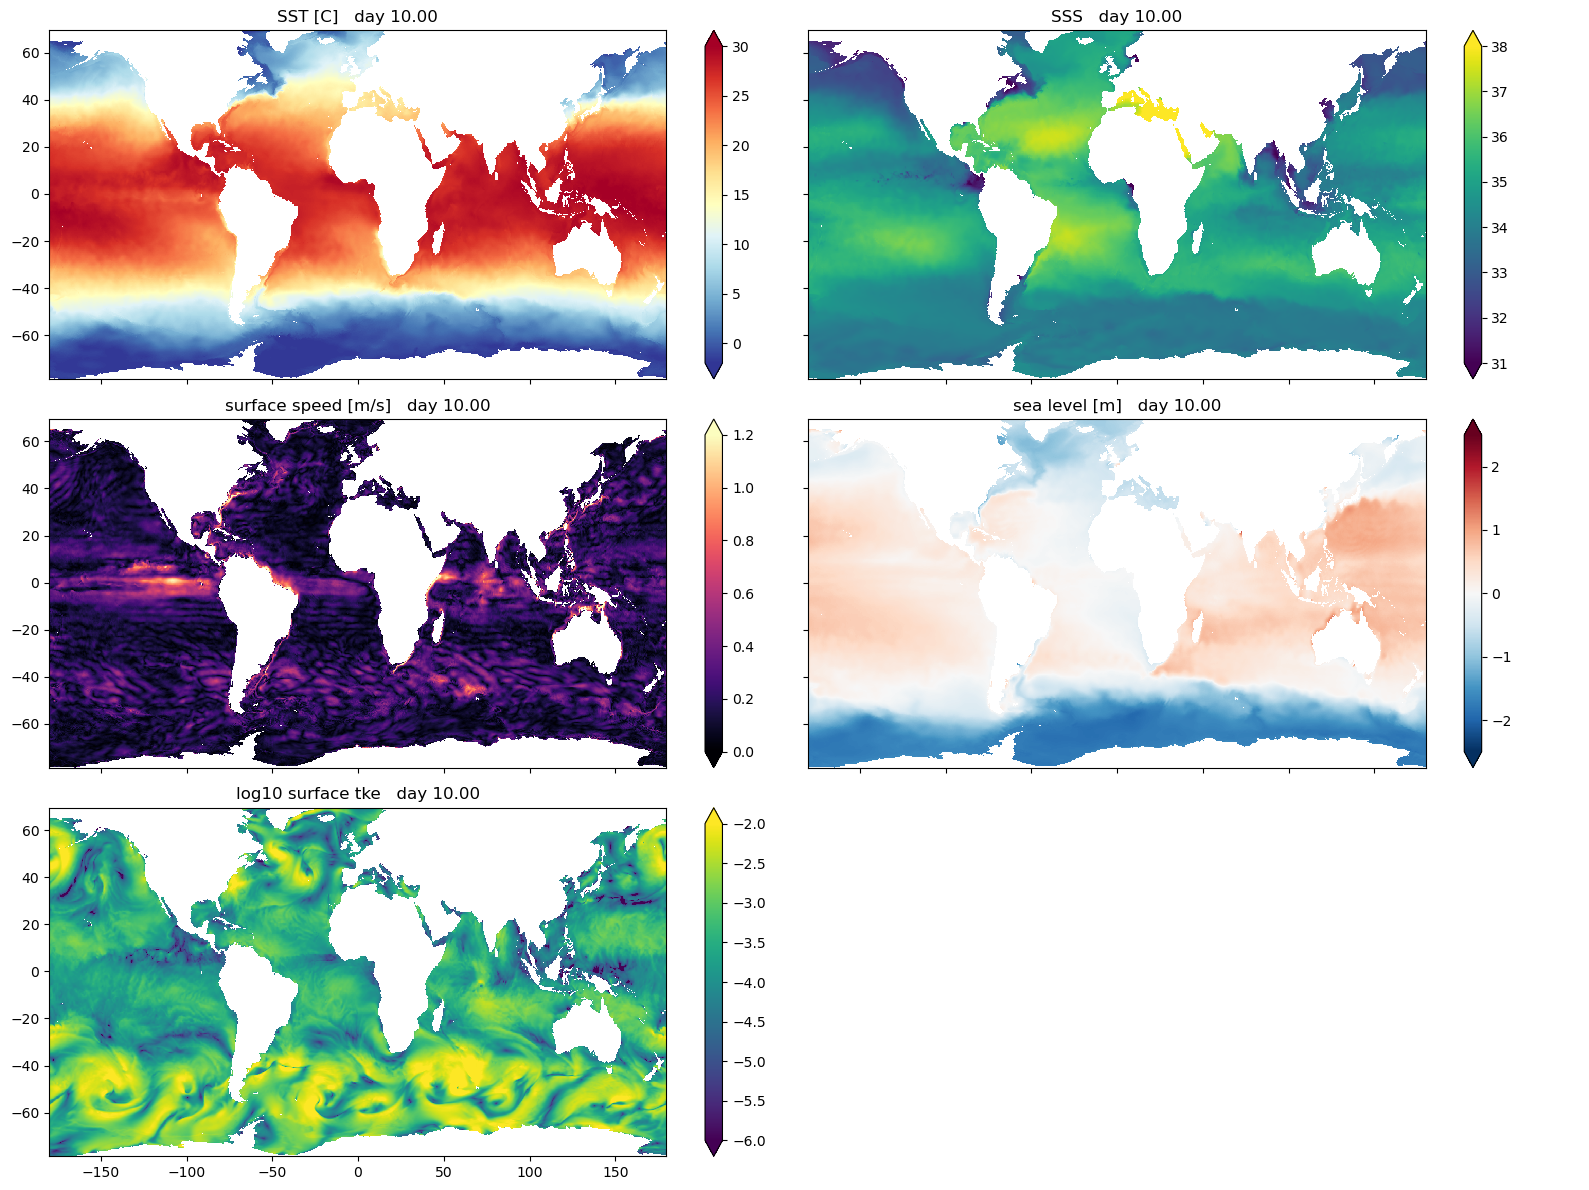

In [4]:
SUB = 3
sub = (slice(None, None, SUB), slice(None, None, SUB))

sst = mask(load('temp', -1), -1)
sss = mask(load('salt', -1), -1)
us, vs = load('u', -1), load('v', -1)
spd = mask(np.hypot(us, vs), -1)
ssh = mask(load('p_s'))/9.81
try:
    tke = mask(load('tke', -1), -1)
except FileNotFoundError:
    tke = None

for nm, a in (('SST [C]', sst), ('SSS', sss), ('speed [m/s]', spd), ('sea level [m]', ssh)):
    print('%-14s min %9.3f  mean %9.3f  max %9.3f  | non-finite %d'
          % (nm, np.nanmin(a), np.nanmean(a), np.nanmax(a),
             int(np.sum(~np.isfinite(a) & (kbot > 0)))))

pan = [(sst, 'SST [C]', dict(vmin=-2, vmax=30, cmap='RdYlBu_r')),
       (sss, 'SSS', dict(vmin=31, vmax=38, cmap='viridis')),
       (spd, 'surface speed [m/s]', dict(vmin=0, vmax=1.2, cmap='magma')),
       (ssh, 'sea level [m]', dict(vmin=-2.5, vmax=2.5, cmap='RdBu_r'))]
if tke is not None:
    pan.append((np.log10(np.maximum(tke, 1e-12)), 'log10 surface tke',
                dict(vmin=-6, vmax=-2, cmap='viridis')))
fig, ax = plt.subplots((len(pan)+1)//2, 2, figsize=(16, 4*((len(pan)+1)//2)),
                       sharex=True, sharey=True)
for a, (fld, ttl, kw) in zip(ax.ravel(), pan):
    h = a.pcolormesh(xt[::SUB], yt[::SUB], fld[sub], shading='auto', **kw)
    plt.colorbar(h, ax=a, extend='both'); a.set_title('%s   day %.2f' % (ttl, t_days))
for a in ax.ravel()[len(pan):]:
    a.axis('off')
fig.tight_layout()

SST max             30.250 at lon  144.800 lat   -1.700  (column 1167 m)
SST min             -1.904 at lon  121.800 lat  -66.473  (column 132 m)
SSS max             40.603 at lon   48.400 lat   28.541  (column 35 m)
SSS min             13.408 at lon   12.500 lat   56.776  (column 35 m)
speed max            3.447 at lon  105.800 lat   -5.890  (column 35 m)
|sea level| max      1.995 at lon  170.900 lat  -70.761  (column 2366 m)


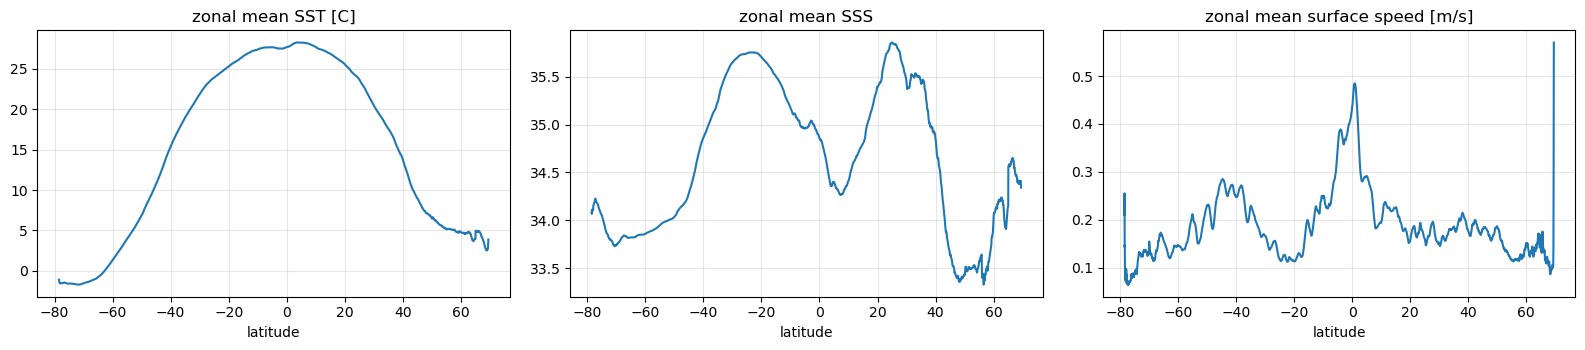

In [5]:
# zonal means, and where the extremes sit
zm = lambda a: np.nanmean(a, axis=1)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
ax[0].plot(yt, zm(sst)); ax[0].set_title('zonal mean SST [C]')
ax[1].plot(yt, zm(sss)); ax[1].set_title('zonal mean SSS')
ax[2].plot(yt, zm(spd)); ax[2].set_title('zonal mean surface speed [m/s]')
for a in ax:
    a.set_xlabel('latitude'); a.grid(alpha=.3)
fig.tight_layout()

for nm, a, f in (('SST max', sst, np.nanargmax), ('SST min', sst, np.nanargmin),
                 ('SSS max', sss, np.nanargmax), ('SSS min', sss, np.nanargmin),
                 ('speed max', spd, np.nanargmax), ('|sea level| max', np.abs(ssh), np.nanargmax)):
    j, i = np.unravel_index(int(f(a)), a.shape)
    print('%-16s %9.3f at lon %8.3f lat %8.3f  (column %.0f m)'
          % (nm, a[j, i], xt[i], yt[j], col_depth[j, i]))

## Sections

Meridional and zonal sections of temperature, salinity and the zonal velocity,
down to `ZMAX`. Each reads one row or column of every block that holds it, so
a section costs a fraction of a 3-D field.

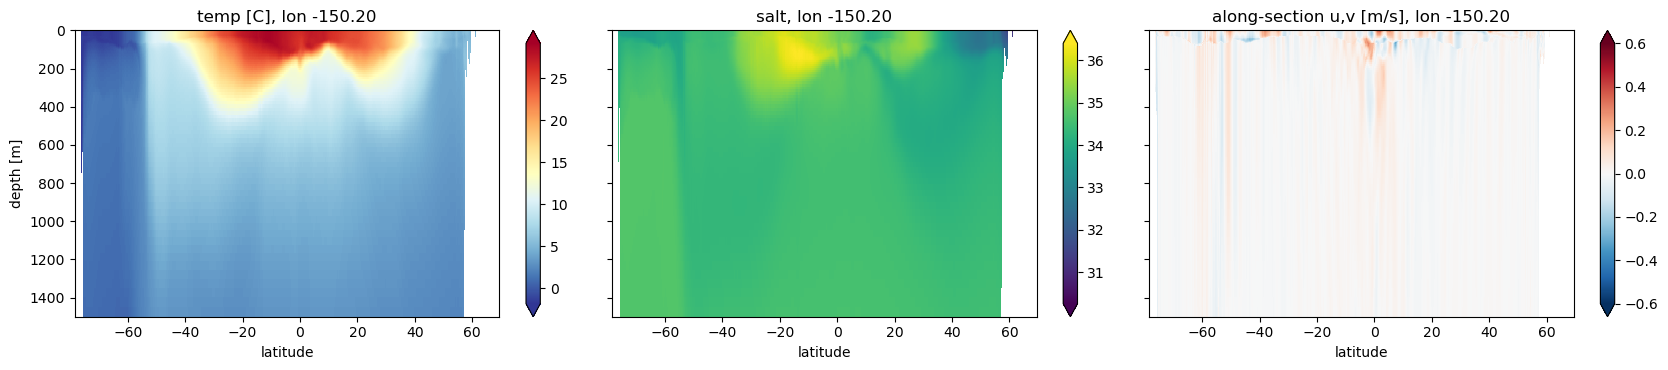

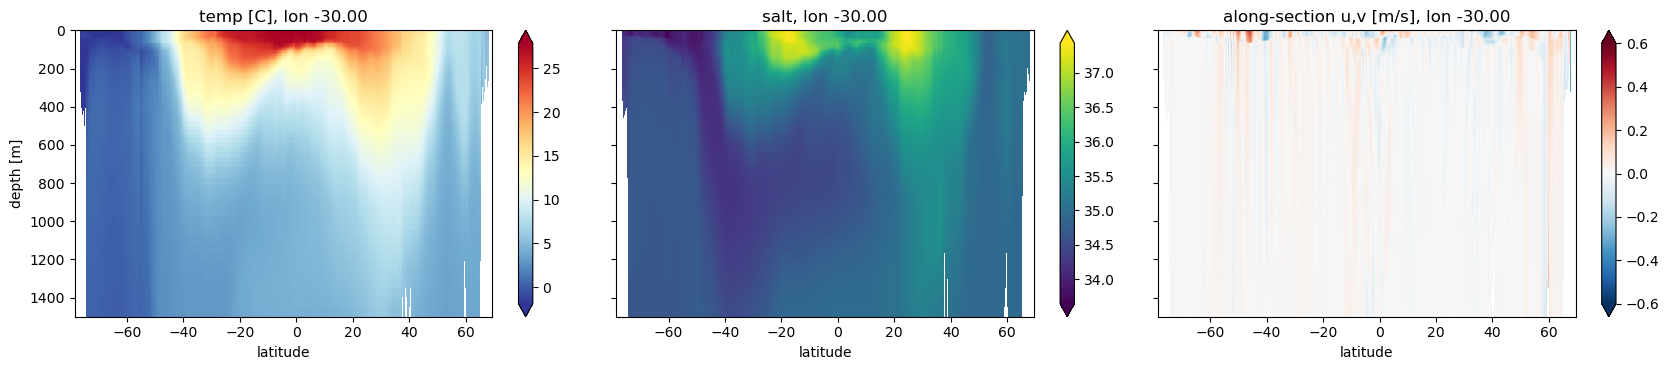

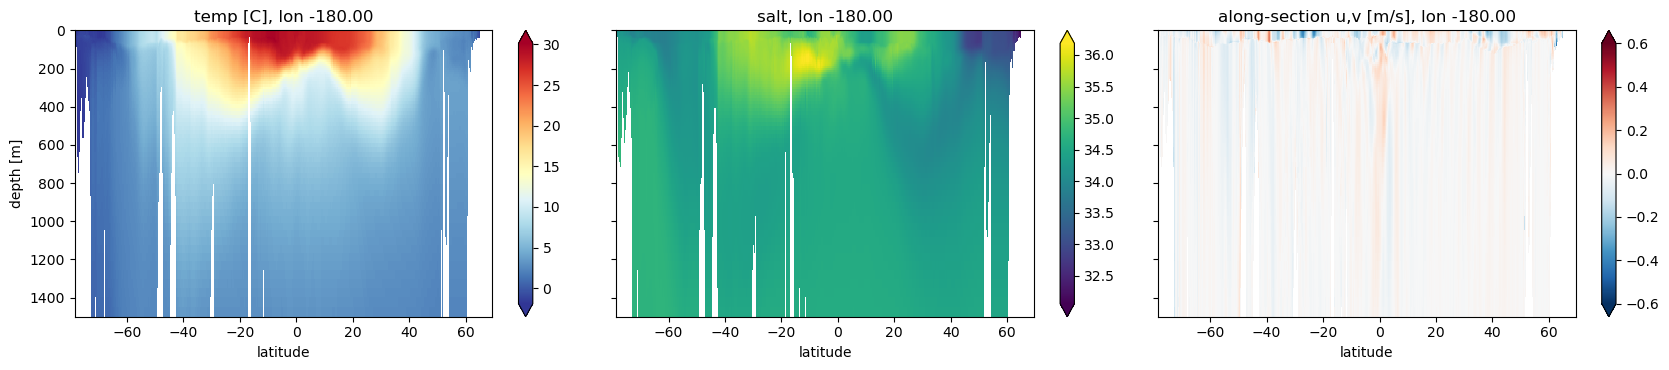

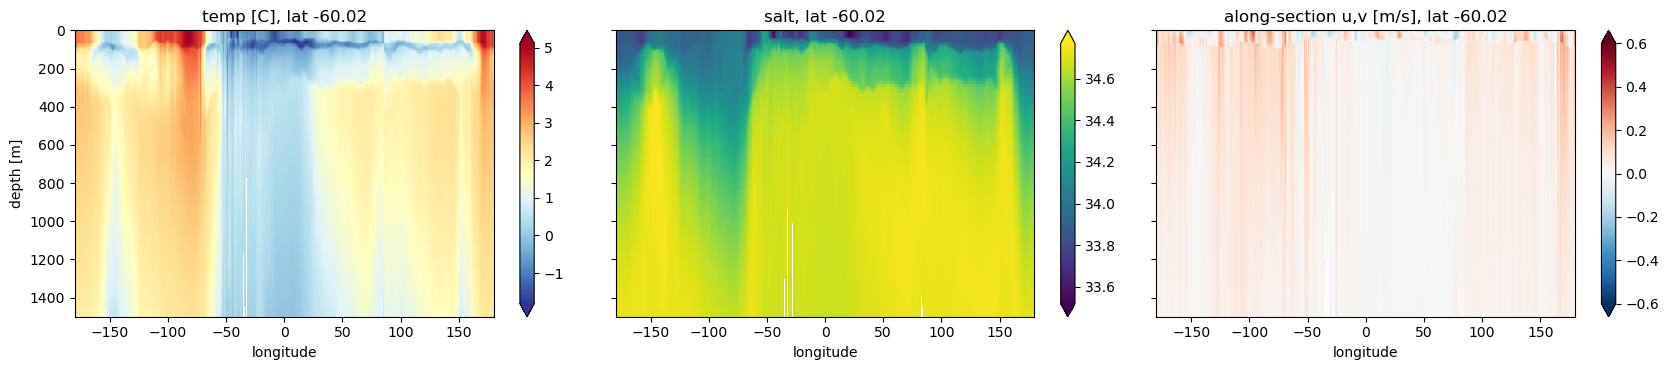

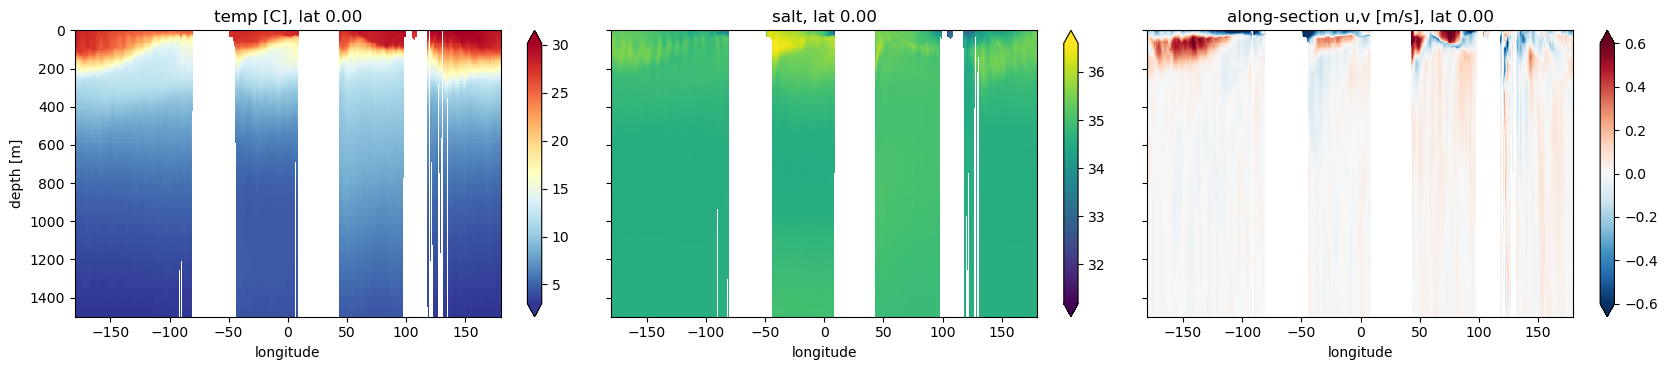

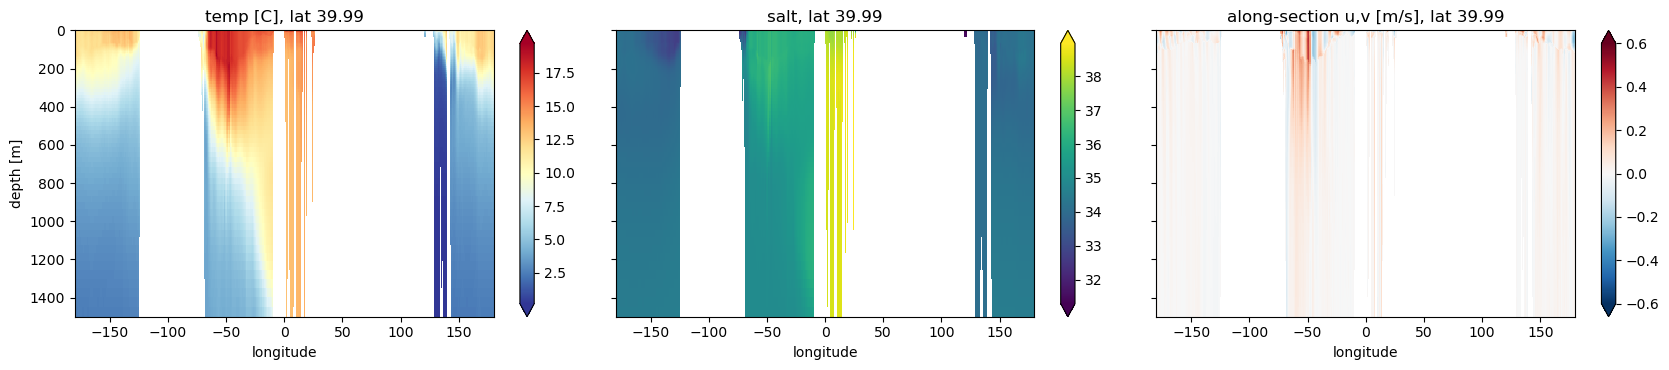

In [6]:
kz = depth_of <= ZMAX                       # the levels to draw

def section_plot(kind, coord):
    if kind == 'lon':
        j, i = ij_of(coord, 0.0)
        T = load_cols('temp', i); S = load_cols('salt', i); U = load_cols('v', i)
        ax2, lab, ttl = yt, 'latitude', 'lon %.2f' % xt[i]
        m = wet[:, :, i]
    else:
        j, i = ij_of(0.0, coord)
        T = load_rows('temp', j); S = load_rows('salt', j); U = load_rows('u', j)
        ax2, lab, ttl = xt, 'longitude', 'lat %.2f' % yt[j]
        m = wet[:, j, :]
    fig, a = plt.subplots(1, 3, figsize=(17, 3.8), sharey=True)
    for k_, (F, t_, kw) in enumerate(((T, 'temp [C]', dict(cmap='RdYlBu_r')),
                                      (S, 'salt', dict(cmap='viridis')),
                                      (U, 'along-section u,v [m/s]',
                                       dict(cmap='RdBu_r', vmin=-0.6, vmax=0.6)))):
        h = a[k_].pcolormesh(ax2, depth_of[kz], np.where(m, F, np.nan)[kz],
                             shading='auto', **kw)
        plt.colorbar(h, ax=a[k_], extend='both'); a[k_].set_title('%s, %s' % (t_, ttl))
        a[k_].set_xlabel(lab)
    a[0].set_ylim(ZMAX, 0); a[0].set_ylabel('depth [m]')
    fig.tight_layout()

for c in SECTION_LON:
    section_plot('lon', c)
for c in SECTION_LAT:
    section_plot('lat', c)

## The problematic area

The dt = 144 run produced a two-cell vertical sawtooth in salinity at
`PROBLEM`, an Antarctic shelf column of about 590 m, and died six model days
in. The cause was the vertical CFL: `w` reached 2 cm/s where the cells are
4.6 m, because on a continental slope `w = u . grad(H)` and one 2.2 km cell
carries the whole depth change.

This section asks whether the present run is anywhere near that. The numbers
to read are `w dt/dz` over the window and the profile at the cell: a smooth
salinity profile and a CFL well under 0.5 means the step is comfortable here.

dt from the snapshot: 72.0 s
in this window: max |w| 1.040e-02 m/s, max vertical CFL 0.088
  the largest CFL sits at lon -149.300 lat -76.271, column 176 m


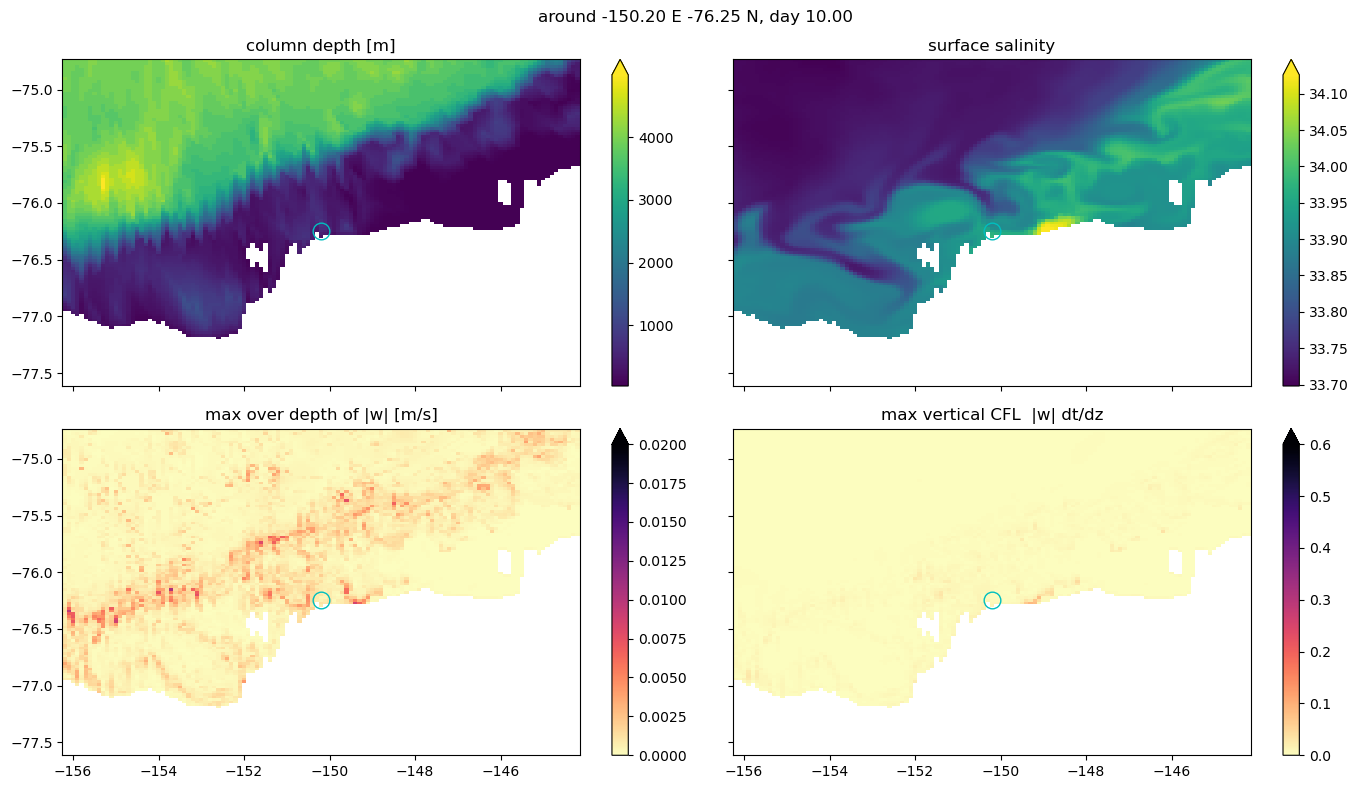

In [7]:
WIN = 60                                     # cells around PROBLEM
jp, ip = ij_of(*PROBLEM)
js, je = max(jp - WIN, 0), min(jp + WIN + 1, ny)
isl = np.arange(ip - WIN, ip + WIN + 1) % nx
xw = xt[isl].astype(float)
xw = xw + 360.0*np.cumsum(np.concatenate([[0], np.diff(xw) < 0]))
mw = wet[:, js:je][:, :, isl]

Tb = load_box('temp', js, je, isl)
Sb = load_box('salt', js, je, isl)
Wb = load_box('w',    js, je, isl)
Ub = load_box('u',    js, je, isl)
Vb = load_box('v',    js, je, isl)

dz3 = dzt[:, None, None]
dt_s = t_days*86400.0/step if step else np.nan
cflw = np.nanmax(np.where(mw, np.abs(Wb)*dt_s/dz3, 0.0), axis=0)
wmax = np.nanmax(np.where(mw, np.abs(Wb), 0.0), axis=0)
print('dt from the snapshot: %.1f s' % dt_s)
print('in this window: max |w| %.3e m/s, max vertical CFL %.3f'
      % (np.nanmax(wmax), np.nanmax(cflw)))
jq, iq = np.unravel_index(int(np.nanargmax(cflw)), cflw.shape)
print('  the largest CFL sits at lon %.3f lat %.3f, column %.0f m'
      % (xw[iq], yt[js+jq], col_depth[js+jq, isl[iq]]))

fig, ax = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
for a, fld, ttl, kw in (
        (ax[0,0], np.where(kbot > 0, col_depth, np.nan)[js:je][:, isl],
         'column depth [m]', dict(cmap='viridis')),
        (ax[0,1], np.where(mw[-1], Sb[-1], np.nan), 'surface salinity', dict(cmap='viridis')),
        (ax[1,0], np.where(kbot > 0, 1.0, np.nan)[js:je][:, isl]*wmax,
         'max over depth of |w| [m/s]', dict(cmap='magma_r', vmin=0, vmax=0.02)),
        (ax[1,1], np.where(kbot > 0, 1.0, np.nan)[js:je][:, isl]*cflw,
         'max vertical CFL  |w| dt/dz', dict(cmap='magma_r', vmin=0, vmax=0.6))):
    h = a.pcolormesh(xw, yt[js:je], fld, shading='auto', **kw)
    a.plot(xw[WIN], yt[jp], 'co', mfc='none', ms=12)
    plt.colorbar(h, ax=a, extend='max'); a.set_title(ttl)
fig.suptitle('around %.2f E %.2f N, day %.2f' % (PROBLEM[0], PROBLEM[1], t_days))
fig.tight_layout()

column at lon -150.200 lat -76.248: 62 wet levels, 589 m
    depth      temp      salt         u         v           w  w dt/dz
      1.0    -1.710    33.953   -0.0148    0.0478   1.464e-06    0.000
      3.1    -1.704    33.953   -0.0151    0.0294  -6.976e-07    0.000
      5.3    -1.699    33.953   -0.0137    0.0161  -1.038e-06    0.000
      7.6    -1.695    33.953   -0.0113    0.0057   3.865e-07    0.000
     10.0    -1.690    33.953   -0.0082   -0.0026   3.671e-06    0.000
     12.5    -1.685    33.953   -0.0044   -0.0092   8.871e-06    0.000
     15.1    -1.680    33.953   -0.0001   -0.0144   1.538e-05    0.000
     17.8    -1.673    33.953    0.0049   -0.0182   2.323e-05    0.001
     20.6    -1.665    33.953    0.0110   -0.0207   3.292e-05    0.001
     23.6    -1.582    33.965    0.0261   -0.0212   4.711e-05    0.001
     26.7    -1.563    33.978    0.0421   -0.0031   6.986e-05    0.002
     29.9    -1.563    33.987    0.0306    0.0036   1.180e-04    0.003
     33.3    -1.575 

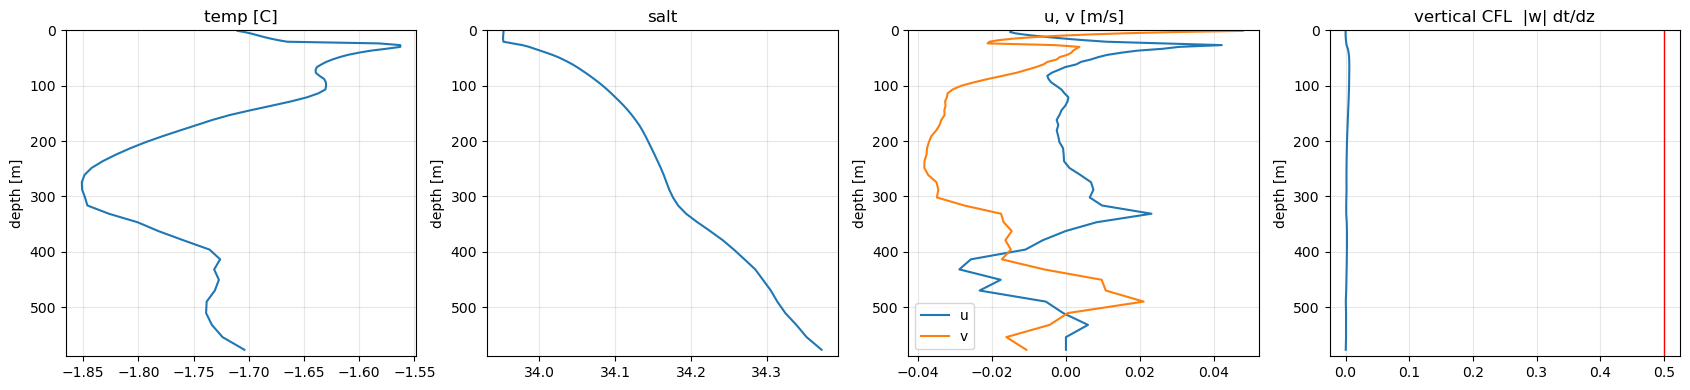

In [8]:
# the column itself, top down, and its neighbours
kw_ = nwet_col[jp, ip]
d = depth_of[nz-kw_:]
prof = dict(temp=Tb[:, WIN, WIN], salt=Sb[:, WIN, WIN], u=Ub[:, WIN, WIN],
            v=Vb[:, WIN, WIN], w=Wb[:, WIN, WIN])
print('column at lon %.3f lat %.3f: %d wet levels, %.0f m' % (xt[ip], yt[jp], kw_,
                                                              col_depth[jp, ip]))
print('%9s %9s %9s %9s %9s %11s %8s' % ('depth', 'temp', 'salt', 'u', 'v', 'w', 'w dt/dz'))
for k in range(nz-1, max(nz-kw_-1, nz-31), -1):
    print('%9.1f %9.3f %9.3f %9.4f %9.4f %11.3e %8.3f'
          % (depth_of[k], prof['temp'][k], prof['salt'][k], prof['u'][k],
             prof['v'][k], prof['w'][k], abs(prof['w'][k])*dt_s/dzt[k]))

fig, ax = plt.subplots(1, 4, figsize=(17, 4))
ax[0].plot(prof['temp'][nz-kw_:], d); ax[0].set_title('temp [C]')
ax[1].plot(prof['salt'][nz-kw_:], d); ax[1].set_title('salt')
ax[2].plot(prof['u'][nz-kw_:], d, label='u'); ax[2].plot(prof['v'][nz-kw_:], d, label='v')
ax[2].legend(); ax[2].set_title('u, v [m/s]')
ax[3].plot(np.abs(prof['w'][nz-kw_:])*dt_s/dzt[nz-kw_:], d)
ax[3].axvline(0.5, color='r', lw=1); ax[3].set_title('vertical CFL  |w| dt/dz')
for a in ax:
    a.set_ylim(col_depth[jp, ip], 0); a.grid(alpha=.3); a.set_ylabel('depth [m]')
fig.tight_layout()

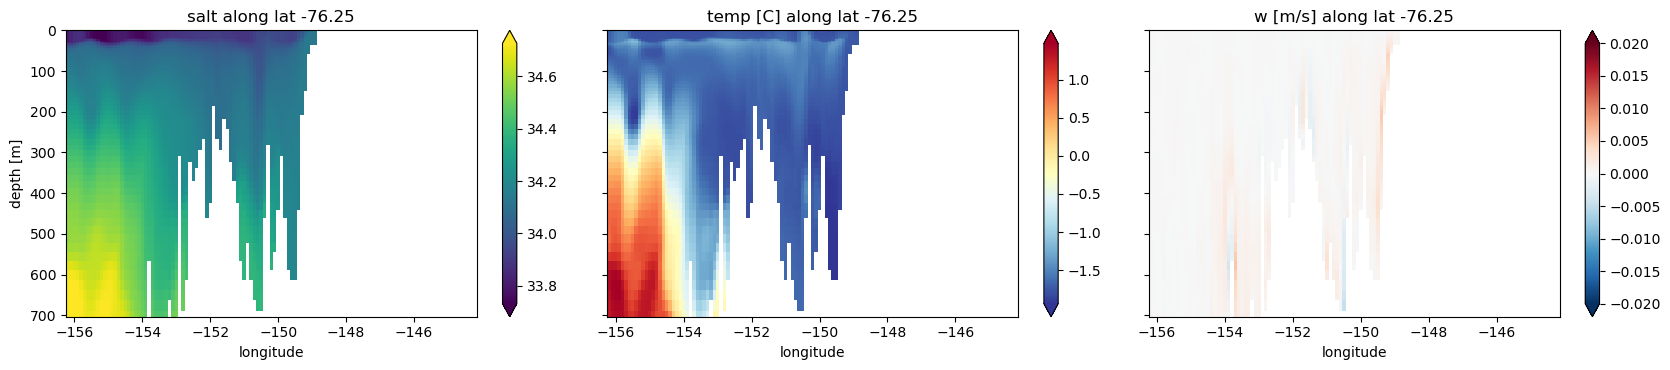

In [9]:
# a section straight through it, so a sawtooth would be visible as stripes
kz2 = depth_of <= min(col_depth[jp, ip]*1.2, 800.0)
fig, ax = plt.subplots(1, 3, figsize=(17, 3.8), sharey=True)
for a, F, ttl, kw in ((ax[0], Sb[:, WIN, :], 'salt', dict(cmap='viridis')),
                      (ax[1], Tb[:, WIN, :], 'temp [C]', dict(cmap='RdYlBu_r')),
                      (ax[2], Wb[:, WIN, :], 'w [m/s]',
                       dict(cmap='RdBu_r', vmin=-0.02, vmax=0.02))):
    h = a.pcolormesh(xw, depth_of[kz2], np.where(mw[:, WIN], F, np.nan)[kz2],
                     shading='auto', **kw)
    plt.colorbar(h, ax=a, extend='both'); a.set_title('%s along lat %.2f' % (ttl, yt[jp]))
    a.set_xlabel('longitude')
ax[0].set_ylim(depth_of[kz2].max(), 0); ax[0].set_ylabel('depth [m]')
fig.tight_layout()

## Global check: is any column close to the limit?

The window above is one place. This pass reads `w` block by block and reports
the largest vertical CFL of the whole domain, where it is, and how many cells
are above 0.3 and 0.5. It is one full read of one 3-D field, so it takes a
while; the thread pool makes it bearable.

one pass over w in 8.0 s
largest vertical CFL 0.202 at lon 3.400 lat -70.057 (column 501 m, 58 levels)
cells above 0.3: 0 | above 0.5: 0


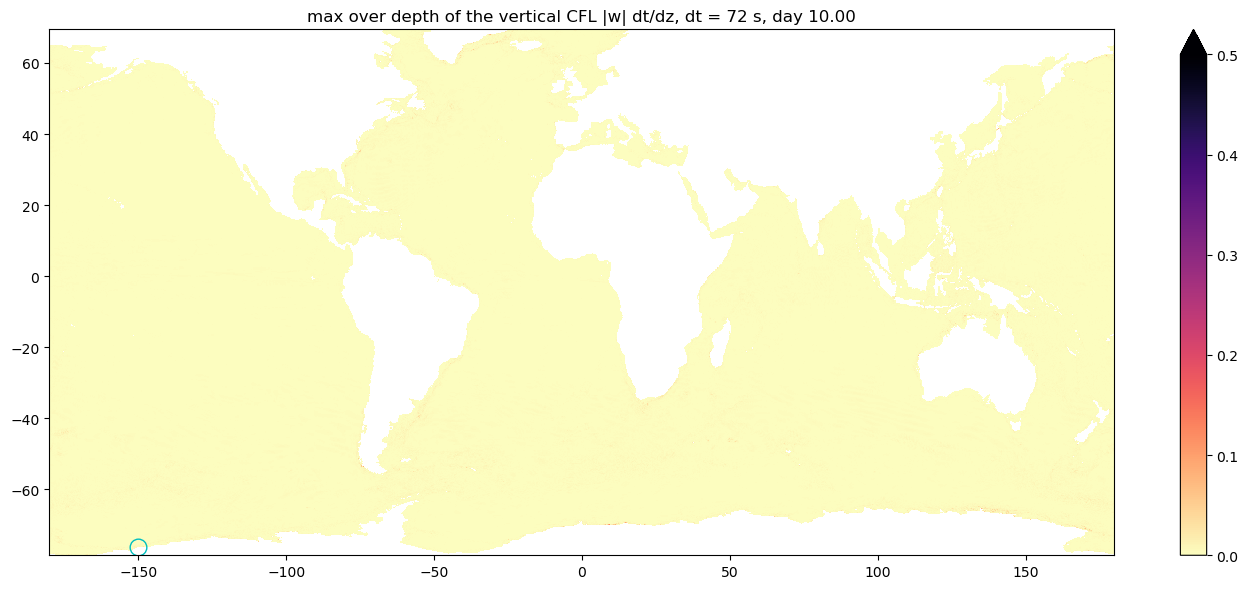

In [10]:
from concurrent.futures import ThreadPoolExecutor
import time as _time
NTHREAD = 16

def _cfl_block(arg):
    pe, j0, j1, i0, i1 = arg
    w = wet[:, j0:j1, i0:i1]
    W = np.where(w, np.abs(np.asarray(np.load(_npy(pe, 'w'), mmap_mode='r'))), 0.0)
    c = W*dt_s/dzt[:, None, None]
    return c.max(axis=0), int((c > 0.3).sum()), int((c > 0.5).sum()), (j0, j1, i0, i1)

_t = _time.time()
cfl2 = np.zeros((ny, nx)); n03 = n05 = 0
with ThreadPoolExecutor(NTHREAD) as ex:
    for cmax, a3, a5, (j0, j1, i0, i1) in ex.map(_cfl_block, BLOCKS):
        cfl2[j0:j1, i0:i1] = cmax; n03 += a3; n05 += a5
print('one pass over w in %.1f s' % (_time.time() - _t))
j, i = np.unravel_index(int(np.nanargmax(np.where(kbot > 0, cfl2, np.nan))), cfl2.shape)
print('largest vertical CFL %.3f at lon %.3f lat %.3f (column %.0f m, %d levels)'
      % (cfl2[j, i], xt[i], yt[j], col_depth[j, i], nwet_col[j, i]))
print('cells above 0.3: %d | above 0.5: %d' % (n03, n05))

fig, a = plt.subplots(figsize=(14, 6))
h = a.pcolormesh(xt[::SUB], yt[::SUB], np.where(kbot > 0, cfl2, np.nan)[sub],
                 shading='auto', vmin=0, vmax=0.5, cmap='magma_r')
plt.colorbar(h, ax=a, extend='max')
a.plot(PROBLEM[0], PROBLEM[1], 'co', mfc='none', ms=12)
a.set_title('max over depth of the vertical CFL |w| dt/dz, dt = %.0f s, day %.2f'
            % (dt_s, t_days))
fig.tight_layout()

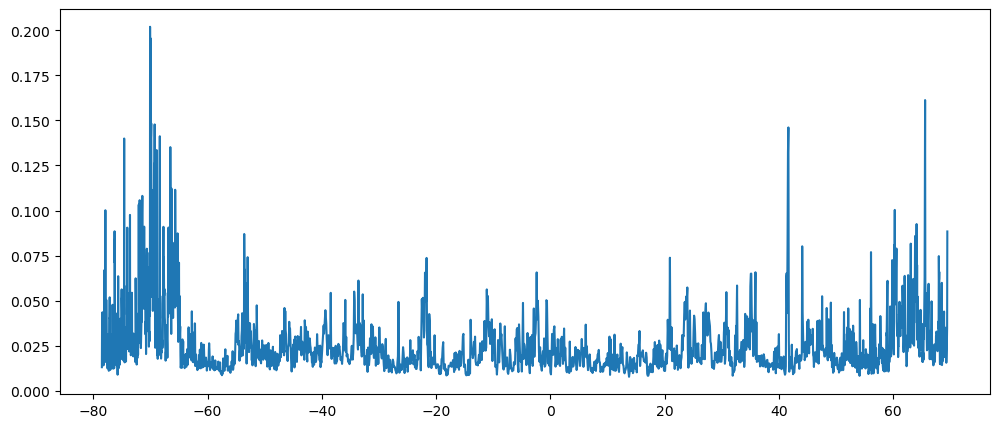

In [12]:
plt.plot(yt,np.max(cfl2,axis=1))

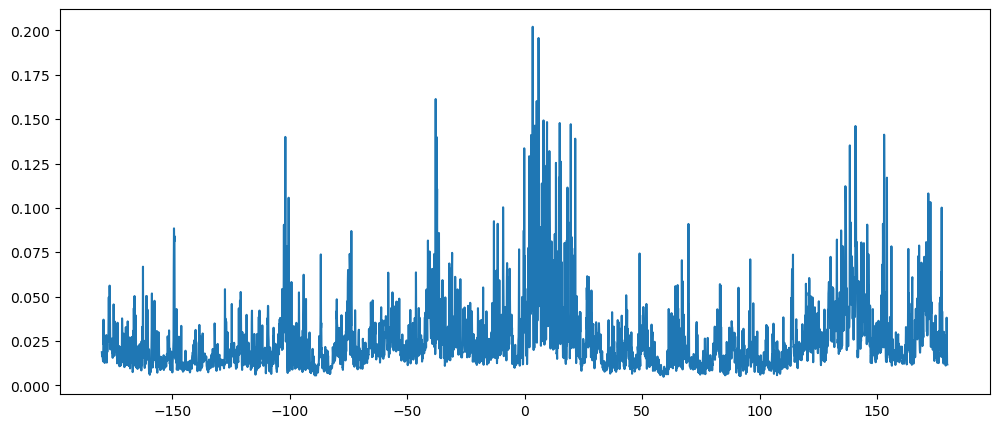

In [13]:
plt.plot(xt,np.max(cfl2,axis=0))